# Batch Normalization

In [2]:
import numpy as np

import matplotlib.pyplot as plt

from sklearn.datasets import make_moons

import tensorflow as tf
from keras.models import Sequential
from keras.layers import Input, Dense, BatchNormalization

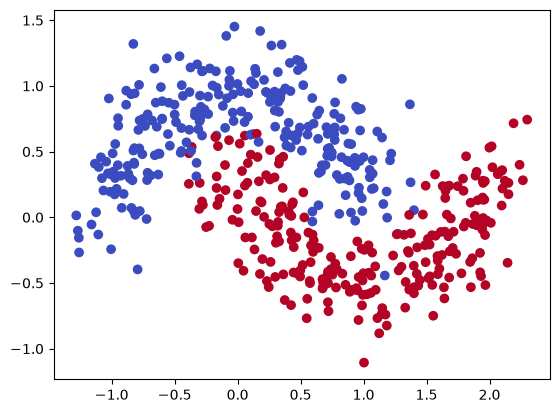

In [12]:
X, y = make_moons(n_samples = 500, noise=0.2, random_state=0)

plt.scatter(X[:, 0], X[:, 1], c = y, cmap = 'coolwarm')
plt.show()

# Without Batch Normalization 

In [13]:
model1 = Sequential([
    Input(shape = (2,)),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(4, activation='relu'),
    Dense(1, activation='sigmoid')
])

model1.compile(optimizer='Adam', loss='binary_crossentropy', metrics=['accuracy'])

history_without_batch_norm = model1.fit(X, y, epochs=100, validation_split=0.2, verbose=0)

# With Batch Normalization

In [14]:
model2 = Sequential([
    Input(shape = (2,)),
    Dense(32, activation='relu'),
    BatchNormalization(),
    Dense(16, activation='relu'),
    BatchNormalization(),
    Dense(4, activation='relu'),
    BatchNormalization(),
    Dense(1, activation='sigmoid')
])

model2.compile(optimizer='Adam', loss='binary_crossentropy', metrics=['accuracy'])

history_with_batch_norm = model2.fit(X, y, epochs=100, validation_split=0.2, verbose=0)

In [15]:
model2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 32)             │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 4)              │            68 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 4)              │            16 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,509 (9.80 KB)

 Trainable params: 801 (3.13 KB)

 Non-trainable params: 104 (416.00 B)

 Optimizer params: 1,604 (6.27 KB)

Batch Normalization adds More Trainable paramaters (γ and β at scaling and shifting step) and Non-trainable parameter ( mean and variance )

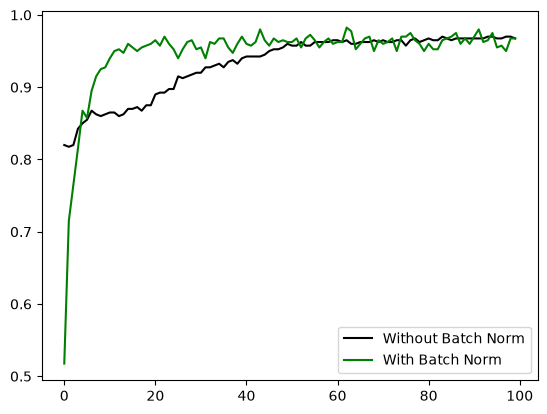

In [18]:
plt.plot(history_without_batch_norm.history['accuracy'], color = 'black', label = 'Without Batch Norm')
plt.plot(history_with_batch_norm.history['accuracy'], color = 'green', label = 'With Batch Norm')
plt.legend()
plt.show()

### With batch Normalization the model reaches 90% accuracy faster than without Batch Norm.